In [1]:
# 24B11IT002-Logistic Regression
#Import pandas to load and work with the CSV dataset
import pandas as pd

# Import train_test_split to divide the dataset
# into training and testing sets
from sklearn.model_selection import train_test_split

# Import LogisticRegression
# This is the Logistic Regression classification algorithm
from sklearn.linear_model import LogisticRegression

In [2]:
# Load the MNIST training dataset
# Make sure train.csv is in the same folder as this notebook
train_data = pd.read_csv("../data/train.csv")

# Display the shape of the dataset
print("Training data shape:", train_data.shape)

Training data shape: (42000, 785)


In [3]:
# X contains the 784 pixel values of each image
# Remove the label column because it is the target
X = train_data.drop("label", axis=1)

# y contains the actual digit labels from 0 to 9
y = train_data["label"]

# Display the shapes
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (42000, 784)
Labels shape: (42000,)


In [4]:
# Original pixel values range from 0 to 255.
# Divide by 255 to convert them to values between 0 and 1.
X = X / 255.0

# Display the minimum pixel value
print("Minimum pixel value:", X.min().min())

# Display the maximum pixel value
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Split the dataset into training and testing portions
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Pixel features
    y,                  # Digit labels
    test_size=0.2,      # 20% of the data is used for testing
    random_state=42,    # Makes the split reproducible
    stratify=y          # Maintains the distribution of digits
)

# Display the resulting shapes
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (33600, 784)
X_test : (8400, 784)
y_train: (33600,)
y_test : (8400,)


In [6]:
# Create the Logistic Regression classifier
logistic_model = LogisticRegression(
    max_iter=1000,       # Allow up to 1000 iterations for training
    solver="lbfgs",      # Optimization algorithm
    random_state=42
)

# Display the model configuration
print(logistic_model)

LogisticRegression(max_iter=1000, random_state=42)


In [7]:
# Train the Logistic Regression model
# using the training images and their labels
logistic_model.fit(X_train, y_train)

# Display a message after training
print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


In [8]:
# Use the trained Logistic Regression model
# to predict the digits in the test dataset
y_pred_lr = logistic_model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:", y_pred_lr[:10])

First 10 predictions: [1 8 6 8 5 7 6 7 7 7]


In [9]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate Logistic Regression accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Calculate weighted precision
lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

# Calculate weighted recall
lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

# Calculate weighted F1-score
lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="weighted"
)

# Display all four metrics
print("Logistic Regression Accuracy :", lr_accuracy)
print("Logistic Regression Precision:", lr_precision)
print("Logistic Regression Recall   :", lr_recall)
print("Logistic Regression F1-Score :", lr_f1)

Logistic Regression Accuracy : 0.9128571428571428
Logistic Regression Precision: 0.9126230583317942
Logistic Regression Recall   : 0.9128571428571428
Logistic Regression F1-Score : 0.9126200390597158


In [10]:
# Error rate is the proportion of incorrect predictions
# Error rate = 1 - accuracy
lr_error_rate = 1 - lr_accuracy

# Count the incorrect predictions
lr_incorrect = (y_test != y_pred_lr).sum()

# Count the correct predictions
lr_correct = (y_test == y_pred_lr).sum()

# Display the results
print("Logistic Regression Error Rate:", lr_error_rate)
print("Logistic Regression Error Rate (%):", lr_error_rate * 100)

print("Correct predictions:", lr_correct)
print("Incorrect predictions:", lr_incorrect)

print("Total predictions:", len(y_test))

Logistic Regression Error Rate: 0.08714285714285719
Logistic Regression Error Rate (%): 8.714285714285719
Correct predictions: 7668
Incorrect predictions: 732
Total predictions: 8400


In [11]:
# Import classification_report
from sklearn.metrics import classification_report

# Generate a detailed classification report
# for every digit from 0 to 9
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.95      0.96      0.96       827
           1       0.93      0.98      0.95       937
           2       0.91      0.90      0.91       835
           3       0.90      0.88      0.89       870
           4       0.92      0.91      0.91       814
           5       0.87      0.86      0.86       759
           6       0.95      0.96      0.96       827
           7       0.93      0.93      0.93       880
           8       0.88      0.85      0.87       813
           9       0.87      0.90      0.89       838

    accuracy                           0.91      8400
   macro avg       0.91      0.91      0.91      8400
weighted avg       0.91      0.91      0.91      8400



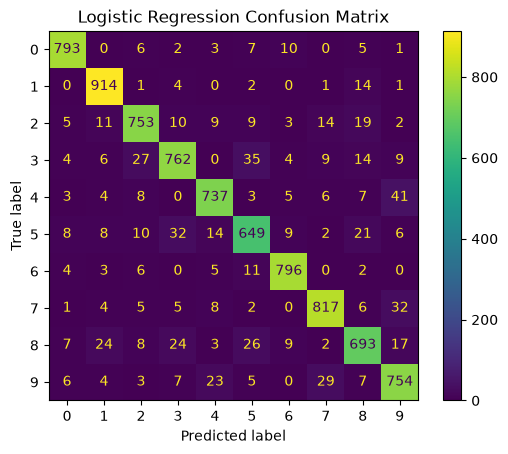

In [12]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Create a visual representation
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

# Display the confusion matrix
disp.plot()

# Add a title
plt.title("Logistic Regression Confusion Matrix")

# Show the graph
plt.show()

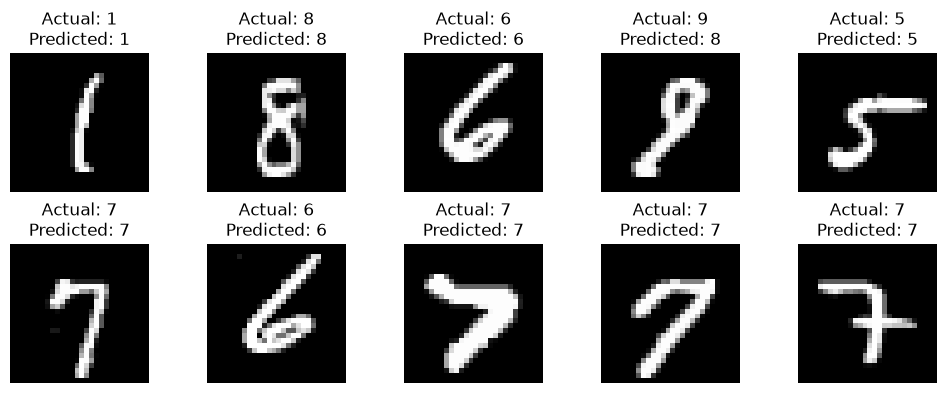

In [13]:
# Create a figure for displaying 10 test images
plt.figure(figsize=(10, 4))

# Display the first 10 test images
for i in range(10):

    # Convert 784 pixels back into a 28 × 28 image
    image = X_test.iloc[i].values.reshape(28, 28)

    # Create a subplot
    plt.subplot(2, 5, i + 1)

    # Display the handwritten digit
    plt.imshow(image, cmap="gray")

    # Display actual and predicted labels
    plt.title(
        f"Actual: {y_test.iloc[i]}\n"
        f"Predicted: {y_pred_lr[i]}"
    )

    # Hide the axis
    plt.axis("off")

# Adjust spacing
plt.tight_layout()

# Display the images
plt.show()

In [14]:
# Import joblib for saving the trained model
import joblib

# Save the Logistic Regression model
joblib.dump(
    logistic_model,
    "logistic_regression_digit_model.pkl"
)

# Confirm that the model was saved
print("Logistic Regression model saved successfully!")

Logistic Regression model saved successfully!
